## Exercise 10.1 (search)

We want to find the largest and smallest values in a long list of numbers. Implement
two algorithms, based on:

1. Iterating over the list entries; and 
1. First applying a built-in sort operation to the list.

Encapsulate each algorithm in a function. To create lists of numbers for testing use, for example:
```python
x = np.random.rand(1000)
```

### Solution

We first create the list of random numbers

In [1]:
import numpy as np
x = np.random.rand(1000)

#### Approach 1

In [2]:
def min_max1(x):
    n = len(x)
    #iterate over each item (bubble sort) this is not very efficient
    while n > 0:
        for i in range(n-1):
            if x[i] > x[i+1]:
                x[i], x[i+1] = x[i+1], x[i]
        n -= 1

    #identify maximum and minimum values once list is sorted
    x_min = x[0]
    x_max = x[-1]
    
    return  x_min, x_max
    
print(min_max1(x))

(np.float64(0.0006992686959792493), np.float64(0.999783093171675))


#### Approach 2

In [3]:
def min_max2(x):
    #use built-in operation to sort the list
    x.sort()
    x_min, x_max = x[0], x[-1]
    
    return x_min, x_max

print(min_max2(x))

(np.float64(0.0006992686959792493), np.float64(0.999783093171675))


In [4]:
## test ##
assert min_max1(x) == min_max2(x)

In practice, we would use the the NumPy function:

In [5]:
print(np.min(x), np.max(x))

0.0006992686959792493 0.999783093171675


## Exercise 10.2 (Newton's method for root finding)

### Background

Newton's method can be used to find a root $x$ of a function $f(x)$ such that
$$
f(x) = 0
$$
A Taylor series expansion of $f$ about $x_{i}$ reads:
$$
f(x_{i+1}) = f(x_{i}) + \left. f^{\prime} \right|_{x_{i}} (x_{i+1} - x_{i}) +  O((x_{i+1} - x_{i})^{2})
$$
If we neglect the higher-order terms and set $f(x_{i+1})$ to zero, we have Newton's method:
\begin{align}
x_{i + 1} &= - \frac{f(x_{i})}{f^{\prime}(x_{i})} + x_{i}
\\
x_{i} &\leftarrow x_{i+1}
\end{align}
In Newton's method, the above is applied iteratively until $\left|f(x_{i + 1})\right|$ is below a tolerance value.

### Task

Develop an implementation of Newton's method, with the following three functions in your implementation:
```python
def newton(f, df, x0, tol, max_it):
    # Implement here

    return x1  # return root
```
where `x0` is the initial guess, `tol` is the stopping tolerance, `max_it` is the maximum number 
of iterations, and 
```python
def f(x):
    # Evaluate function at x and return value


def df(x):
    # Evaluate df/dx at x and return value

```

Your implementation should raise an exception if the maximum number of iterations (`max_it`)
is exceeded.

Use your program to find the roots of:

$$
f(x) = \tan(x) - 2x
$$

between $-\pi/2$ and $\pi/2$. Plot $f(x)$ and $f^{\prime}(x)$ on the same graph, 
**and show all the roots** computed by Newton's method.

Newton's method can be sensitive to the starting value. Make sure you find the root around $x = 1.2$. 
What happens if you start at $x = 0.9$? It may help to add a print statement in the iteration loop, 
showing $x$ and $f$ at each iteration.


### Extension (optional)

For a complicated function we might not know how to compute the derivative, or it may be very complicated
to evaluate. Write a function that computes the *numerical derivative* of $f(x)$ by evaluating 
$(f(x + dx) - f(x - dx)) / (2dx)$, where $dx$ is small. How should you choose $dx$?

### Solution

We first implement a Newton solver function:

In [6]:
import numpy as np

#I added an iteration argument because it was the best way I could think of guarding against
#an infinite loop when performing recursion
def newton(f, df, x, tol=1e-8, max_it=20, it=0):
    """Find root of equation defined by function f(x) where df(x) is
    first derivative and x is the initial guess.Optional arguments tol 
    (tolerance) and max_it (maximum number of iterations)"""
    #guard against infinite loop (raises exception)
    if it < max_it:
        #base case
        if np.abs(f(x)) < tol:
            return x
        #recursive case
        else:
            it += 1
            x = -(f(x)/df(x)) + x
            return newton(f, df, x, tol, max_it, it)

    #raises error if recursive loop is broken (ie. it>=max_it)
    raise RuntimeError("Maximum number of iterations was exceeded")

We now provide implementations of `f` and `df`, and find the roots:

In [7]:
def f(x):
    #compute and return f
    f =  np.tan(x) - 2*x
    return f

def df(x):
    #compute and return df
    df = (1/(np.cos(x)**2)) - 2
    return df

In [8]:
## tests ##

# Find roots near -1.2, 0.1, and 1.2
xroots = np.array((newton(f, df, -1.2),
                   newton(f, df, 0.1),
                   newton(f, df, 1.2)))
#I used this to print roots for my own visualisation. Now a comment
#print(xroots)
assert np.isclose(xroots, [-1.16556119e+00, 2.08575213e-10, 1.16556119e+00]).all()

#testing result if we start at 0.9
print(newton(f, df, 0.9))

#My RuntimeError implementation works :)
#The value of x diverges from the root and the function surpasses the maximum number of iterations
#This means there is an inflection point between 0.9 and the root, as a result the prediction leads us away from it

RuntimeError: Maximum number of iterations was exceeded

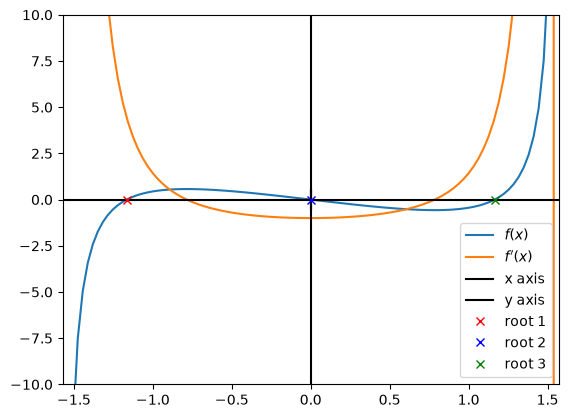

In [16]:
# We can visualise the result:
    
%matplotlib inline
import matplotlib.pyplot as plt

# Plot f and df/dx
x = np.linspace((-np.pi)/2, (np.pi/2), 100)
zeros = np.zeros(100)
plt.plot(x, f(x), label='$f(x)$')
plt.plot(x, df(x), label="$f^{\\prime}(x)$")
plt.plot(x, zeros, label="x axis", color="black")
plt.plot(zeros, f(x), label="y axis", color="black")

# Add location of roots to plot
plt.plot(-1.16556119, 0, 'xr', label="root 1")
plt.plot(0, 0, 'xb', label="root 2")
plt.plot(1.16556119, 0, 'xg', label="root 3")

#some formatting to make the plot more readable
plt.ylim(-10, 10)
plt.xlim(-np.pi/2, np.pi/2)
plt.legend()
plt.show()

For the extension, we can replace the function `df(x)` with a new version

In [10]:
def df(x):
    # Try changing dx to 1e-15 or smaller
    dx = 1e-11
    dy = f(x+dx) - f(x)
    
    #rather than actually differentiating the function algebraically, we apply differentiation principles
    #we compute dy/dx for very small vaues of dx. If dx < 1e-15, the precision is not high enough to properly evaluate df
    #and it is considered to be 0, breaking our implementation
    df = dy/dx

    return df

#this 

In [11]:
## tests ##

# Find roots near -1.2, 0.1, and 1.2
xroots = np.array((newton(f, df, -1.2),
                   newton(f, df, 0.1),
                   newton(f, df, 1.2)))
assert np.isclose(xroots, [-1.16556119e+00, 2.08575213e-10, 1.16556119e+00]).all()

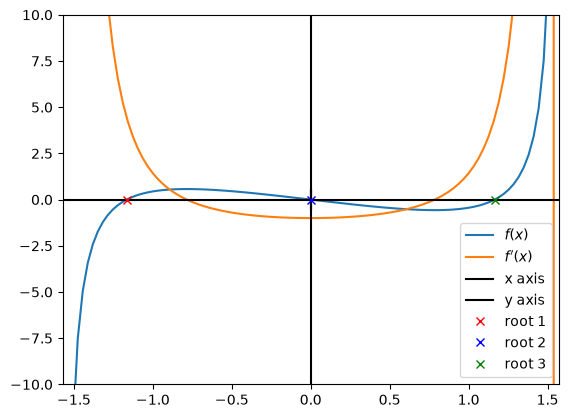

In [15]:
# Plot f, f' and roots

%matplotlib inline
import matplotlib.pyplot as plt

# Plot f and df/dx
x = np.linspace((-np.pi)/2, (np.pi/2), 100)
zeros = np.zeros(100)
plt.plot(x, f(x), label='$f(x)$')
plt.plot(x, df(x), label="$f^{\\prime}(x)$")
plt.plot(x, zeros, label="x axis", color="black")
plt.plot(zeros, f(x), label="y axis", color="black")

# Add location of roots to plot
plt.plot(-1.16556119, 0, 'xr', label="root 1")
plt.plot(0, 0, 'xb', label="root 2")
plt.plot(1.16556119, 0, 'xg', label="root 3")

#some formatting to make the plot more readable
plt.ylim(-10, 10)
plt.xlim(-np.pi/2, np.pi/2)
plt.legend()
plt.show()

In practice, we could use the Newton function `scipy.optimize.newton` from SciPy (https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.newton.html) rather than implementing our own function.

## Exercise 10.3 (optional, low pass image filter)

Image files can be loaded as NumPy arrays displayed with Matplotlib. An imported colour image is stored as a 
three-dimensional NumPy array of floats. The shape of the array is `[0:nx, 0:ny, 0:3]`. 
where `nx` is the number of pixels in the $x$-direction, `ny` is the number of pixels in the $y$-direction,
and the third axis is for the colour component (RGB: red, green and blue) intensity.
For a greyscale image, for each pixel we have either an integer (typically in the range [0, 255]) or a float (in the range [0, 1.0]).

Below we fetch an image and display it:

In [13]:
%matplotlib inline
import PIL
import urllib
import matplotlib.pyplot as plt

# Import image
url = 'https://raw.githubusercontent.com/matplotlib/matplotlib.github.com/main/3.5.3/_images/stinkbug.png'
img = np.array(PIL.Image.open(urllib.request.urlopen(url)))

# Check type and shape
print(type(img))
print(f"Image array shape: {img.shape}")
print(f"Image pixel type: {img.dtype}")

# Convert pixel data from 8-bit integers [0, 255] to floats in range [0, 1]
img = np.float64(img) / 255

# Display image
plt.imshow(img);

AttributeError: module 'urllib' has no attribute 'request'

The task is to write a *function* that applies a particular low-pass filter algorithm to an image array 
and  returns the  filtered image. With this particular filter, the value of a pixel in the filtered image 
is equal to the average value of the four neighbouring pixels in the original image. For the `[i, j, :]` pixel, 
the neighbours are  `[i, j+1, :]`, `[i, j-1, :]`, `[i+1, j, :]` and  `[i-1, j, :]`. 

Run the filter algorithm multiple times on the above image to explore the effect of the filter.

*Hint*: To create a NumPy array of zeros, `B`,  with the same shape as array `A`, use:
```python
import numpy as np
B = np.zeros_like(A)
```

In [14]:
#The program above meant to fetch the image does not work, but I still coded 
#an attempt at the test, although it might not actually work

def low_pass(img):
    #my function assumes the image has been converted to floats [0,1] since this 
    #is the specific case we are dealing with
    low_img = np.zeros_like(img)

    #calculate average of neighbours and assign to each pixel in new image
    for i in range(len(img)):
        for j in range(len(img[i, j, :])):
            average = (img[i, j+1, :] + img[i, j-1, :] + img[i+1, j, :] + img[i-1, j, :])/4
            low_img[i, j, :] = average

    return low_img

plt.imshow(low_pass(img))

NameError: name 'img' is not defined